# Airline Passenger Satisfaction — Who are the passengers with wifi = 0?

**Why this notebook.** In the training set, the 3,103 passengers who rated the inflight wifi **0** are
**99.7 % satisfied**, against 41.6 % for the other passengers, and the selected model predicts all of them correctly
on the test set. This is the main limitation of our report (section 5), but we do not know yet who these
passengers are.

**Question.** Is this pattern a **real behaviour** of a group of passengers, or an **artifact of the survey**
(the way the data was collected)? We answer four questions, then conclude.

| Section | Question |
|---|---|
| 1 | Who are they? (type of travel, class, loyalty) |
| 2 | Do they have a different profile? (age, distance, delay) |
| 3 | Is it just an effect of the type of passenger? (comparison inside each type of travel × class segment) |
| 4 | Do they have other 0 ratings? |
| 5 | Conclusion |

Only the **training set** is used: the test file must not influence any analysis or choice.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make the src package importable from notebooks/

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.data import load_split, split_features_target
from src.utils import load_config
from src.visualization import TARGET_COLORS

config = load_config()
RATINGS = config["features"]["ratings"]
OTHER_SERVICES = [column for column in RATINGS if column != "inflight_wifi_service"]

X, y = split_features_target(load_split(config, "train"), config)
no_wifi = X["inflight_wifi_service"] == 0
group = no_wifi.map({True: "wifi = 0", False: "other passengers"})

print(no_wifi.sum(), round(y[no_wifi].mean(), 3))
print(f"satisfaction of the other passengers: {y[~no_wifi].mean():.3f}")

3103 0.997
satisfaction of the other passengers: 0.416


**Check:** 3,103 passengers with wifi = 0, 99.7 % satisfied (the value given in notebook 01, section 3.1).
The other passengers are 41.6 % satisfied.

## 1. Who are they?

In [2]:
profile = pd.concat({
    column: pd.crosstab(group, X[column], normalize="index")
    for column in ["type_of_travel", "class", "customer_type", "gender"]
}, axis=1)
display((profile.T * 100).round(1).rename_axis(["column", "level"]))

inflight_wifi_service             other passengers  wifi = 0
column         level                                        
type_of_travel Business travel                68.7      79.0
               Personal Travel                31.3      21.0
class          Business                       47.3      63.8
               Eco                            45.5      29.9
               Eco Plus                        7.2       6.3
customer_type  Loyal Customer                 81.9      77.7
               disloyal Customer              18.1      22.3
gender         Female                         50.7      51.3
               Male                           49.3      48.7

**Interpretation**

- The wifi = 0 group contains **more business travellers** (79.0 % vs 68.7 %) and **more Business-class
  passengers** (63.8 % vs 47.3 %): the segment that is the most often satisfied. Part of their satisfaction
  could therefore come from who they are.
- But this cannot explain 99.7 %: **21 % of them travel for personal reasons and 30 % fly Eco**, two groups
  that are rarely satisfied. They are also slightly **less loyal** (77.7 % vs 81.9 %), which should lower
  their satisfaction, not raise it.
- Gender is the same in both groups (51 % women).

## 2. Do they have a different profile?

In [3]:
numeric = ["age", "flight_distance", "departure_delay_in_minutes", "arrival_delay_in_minutes"]
display(X.groupby(group)[numeric].median().T.rename_axis("median"))

inflight_wifi_service,other passengers,wifi = 0
median,,
age,40.0,38.0
flight_distance,844.0,749.0
departure_delay_in_minutes,0.0,0.0
arrival_delay_in_minutes,0.0,0.0


**Interpretation**

- The medians are very close: **38 vs 40 years**, **749 vs 844 miles**, and no delay in both groups.
- These passengers are neither on longer flights nor in a specific age group: their profile does not explain
  their satisfaction.

## 3. Is it just an effect of the type of passenger?

Section 1 showed that the wifi = 0 group has more business travellers in Business class. Type of travel and
class could be **confounding variables**: they could explain the satisfaction instead of the wifi rating.
To control for them, we compare the two groups **inside each type of travel × class segment**, that is,
between passengers who look alike.

In [4]:
segments = [X["type_of_travel"], X["class"]]
by_segment = pd.DataFrame({
    "wifi = 0: satisfied": y[no_wifi].groupby(segments).mean(),
    "wifi = 0: passengers": y[no_wifi].groupby(segments).size(),
    "others: satisfied": y[~no_wifi].groupby(segments).mean(),
    "others: passengers": y[~no_wifi].groupby(segments).size(),
})
display(by_segment.style.format({"wifi = 0: satisfied": "{:.1%}", "others: satisfied": "{:.1%}"}))

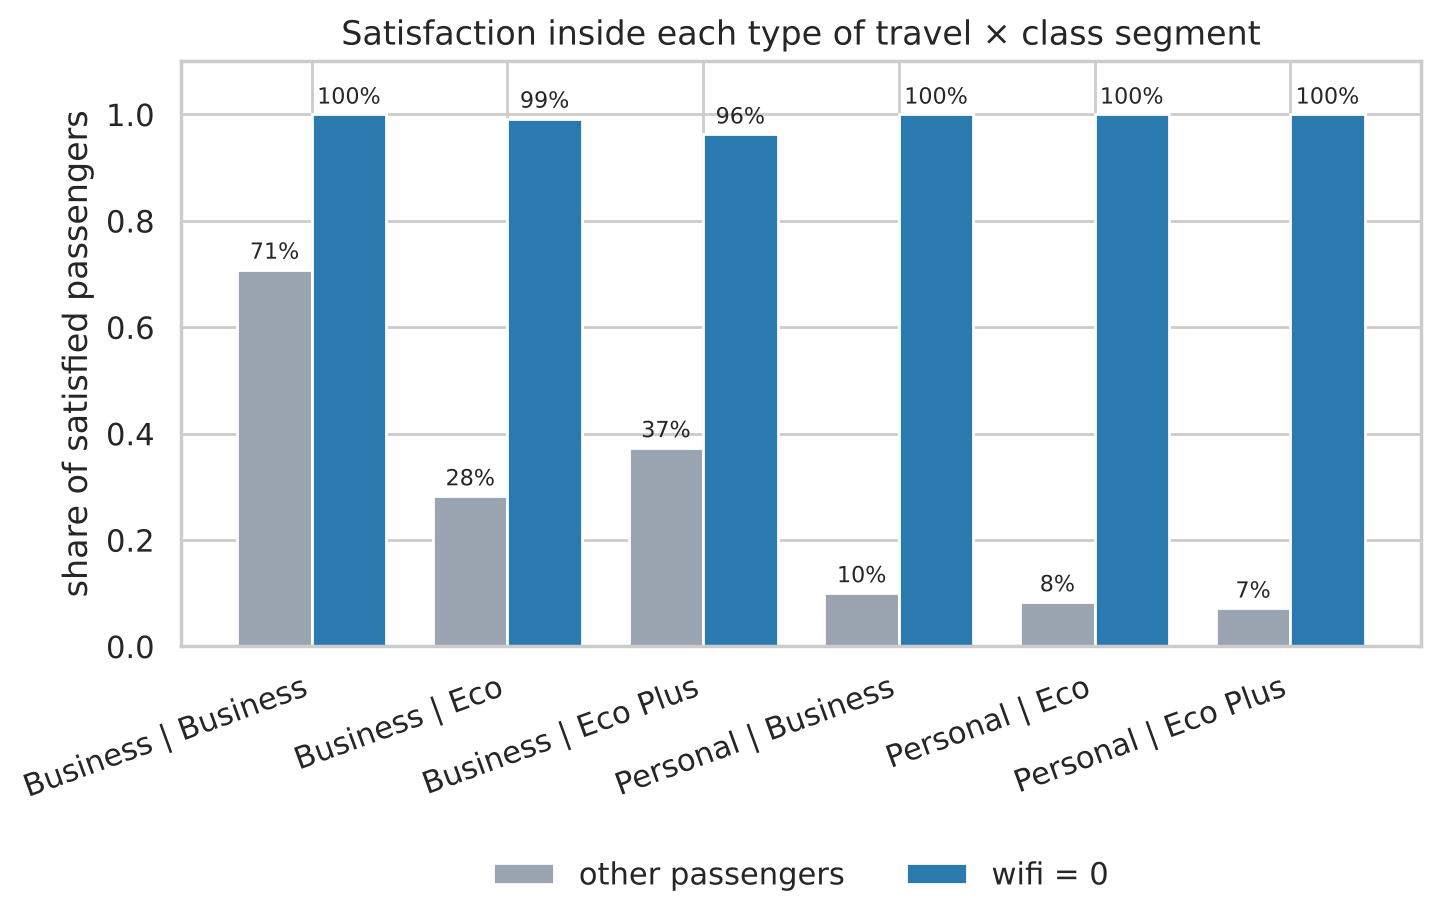

In [5]:
rates = by_segment[["others: satisfied", "wifi = 0: satisfied"]]
labels = [f"{travel.replace(' travel', '').replace(' Travel', '')} | {cls}" for travel, cls in rates.index]

fig, ax = plt.subplots(figsize=(8, 3.8))
positions = range(len(rates))
width = 0.38
for shift, column, color, name in [(-width / 2, "others: satisfied", TARGET_COLORS[0], "other passengers"),
                                   (width / 2, "wifi = 0: satisfied", TARGET_COLORS[1], "wifi = 0")]:
    bars = ax.bar([p + shift for p in positions], rates[column], width, color=color, label=name)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in rates[column]], fontsize=8, padding=2)
ax.set_xticks(list(positions), labels, rotation=20, ha="right")
ax.set(ylabel="share of satisfied passengers", ylim=(0, 1.1),
       title="Satisfaction inside each type of travel × class segment")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
plt.show()

**Interpretation**

- **The gap stays huge inside every segment.** The clearest case is **personal travellers in Eco**, one of the
  least satisfied groups of the dataset: 8.3 % of them are satisfied, but **all 537 who rated the wifi 0 are
  satisfied (100 %)**. The same holds for business travellers in Eco: 99.2 % against 28.2 %.
- Comparing passengers who look alike removes the effect of the type of travel and the class. Since the gap
  stays large everywhere (from 29 points for business travel in Business class to 93 points for personal travel
  in Eco Plus), **the type of passenger does not explain the pattern**: the wifi = 0 passengers are not
  simply "the satisfied kind of passenger".

## 4. Do they have other 0 ratings?

In [6]:
zeros = pd.DataFrame({
    "share of 0 (wifi = 0)": (X.loc[no_wifi, OTHER_SERVICES] == 0).mean(),
    "share of 0 (others)": (X.loc[~no_wifi, OTHER_SERVICES] == 0).mean(),
    # mean of the real ratings (1 to 5), zeros excluded
    "mean rating (wifi = 0)": X.loc[no_wifi, OTHER_SERVICES].replace(0, float("nan")).mean(),
    "mean rating (others)": X.loc[~no_wifi, OTHER_SERVICES].replace(0, float("nan")).mean(),
}).sort_values("share of 0 (wifi = 0)", ascending=False)
display(zeros.style.format({"share of 0 (wifi = 0)": "{:.1%}", "share of 0 (others)": "{:.1%}",
                            "mean rating (wifi = 0)": "{:.2f}", "mean rating (others)": "{:.2f}"}))

any_other_zero = (X[OTHER_SERVICES] == 0).any(axis=1)
print(f"at least one other 0: wifi = 0 {any_other_zero[no_wifi].mean():.1%}, others {any_other_zero[~no_wifi].mean():.1%}")
print("ease of online booking among wifi = 0 passengers:")
print(X.loc[no_wifi, "ease_of_online_booking"].value_counts().sort_index().to_string())

,share of 0 (wifi = 0),share of 0 (others),mean rating (wifi = 0),mean rating (others)
ease_of_online_booking,93.2%,1.6%,1.08,2.89
departure_arrival_time_convenient,46.1%,3.8%,3.84,3.21
online_boarding,40.3%,1.2%,3.78,3.32
leg_room_service,4.7%,0.3%,3.17,3.37
food_and_drink,1.8%,0.1%,3.21,3.21
cleanliness,0.3%,0.0%,3.36,3.28
inflight_entertainment,0.3%,0.0%,3.11,3.37
gate_location,0.0%,0.0%,2.83,2.98
seat_comfort,0.0%,0.0%,3.53,3.44
on_board_service,0.0%,0.0%,3.29,3.39


at least one other 0: wifi = 0 94.1%, others 5.1%
ease of online booking among wifi = 0 passengers:
ease_of_online_booking
0    2893
1     205
3       1
4       2
5       2


**Interpretation**

- **The zeros come in a block.** 94.1 % of the wifi = 0 passengers have at least one other 0, against 5.1 % of
  the others. The zeros fall on the **digital and pre-flight services only**: ease of online booking
  (**93.2 %** against 1.6 %), departure/arrival time (46.1 %) and online boarding (40.3 %).
- **Online booking is almost never really rated**: 2,893 of these passengers gave 0, 205 gave 1, and only
  5 gave 3, 4 or 5. A whole part of the questionnaire seems to be missing for them.
- **The on-board services are rated normally** (seat comfort, cleanliness, staff: almost no 0), and their
  ratings are **ordinary**, between 3.1 and 3.6 on average, like those of the other passengers. Yet the other
  passengers, with similar ratings, are only 41.6 % satisfied. Nothing in their answers explains 99.7 %.

## 5. Conclusion

**Most likely a survey artifact**, although it cannot be proven with this data alone.

What makes us lean towards an artifact:

1. **The type of passenger does not explain it** (section 3): the gap stays large inside every segment,
   for example 100 % against 8 % for personal travellers in Eco.
2. **The zeros are grouped on the digital services** (section 4), and online booking is almost always 0 or 1.
   This looks like a part of the questionnaire that was not filled in, or a group of rows built differently,
   rather than a real choice of the passengers.
3. **Their other ratings are average** while their satisfaction is almost perfect: their own answers do not
   justify it.

What we cannot say: Kaggle documents 0 as "Not Applicable" for the wifi only and does not describe how the
survey was collected, so we cannot know where the pattern comes from. To be sure, we would need the
**documentation of the data collection**, or a **new sample** from the same airline to check whether the pattern
appears again.

**Consequence for the model.** The selected model has learned that "wifi = 0" means "satisfied". On real data
without this artifact, it would predict "satisfied" for every passenger who does not rate the wifi, so its
96.4 % test accuracy is somewhat optimistic for these passengers. The robustness experiment without the wifi
flag (`configs/config_nowifi.yaml`) measures how much the model depends on it.